# 04 - Classificação: k-NN, SVM, Random Forest, GBM, Naive Bayes e Rede Neural

Este notebook utiliza a classe `Classifier` de `src/classifier.py` (e a `Avalia_modelo` de `src/avalia_modelo.py`), seguindo o padrão da aula `07-aula-09-03-treinamento_classif`.

**Objetivo:** prever a recidiva do câncer (`classe`) a partir dos genótipos dos pacientes.

**Algoritmos testados** (implementados no `Classifier`):

| Código | Algoritmo | Ideia principal |
|---|---|---|
| `knn` | k-Nearest Neighbors | Classifica pela classe dos *k* vizinhos mais próximos |
| `svm` | Support Vector Machine | Busca o hiperplano de maior margem entre as classes |
| `rf` | Random Forest | Conjunto de árvores de decisão treinadas com *bagging* |
| `gbm` | Gradient Boosting | Árvores treinadas em sequência, corrigindo os erros anteriores |
| `nb` | Gaussian Naive Bayes | Teorema de Bayes assumindo independência entre as features |
| `nn` | Rede Neural (MLP) | Perceptron multicamadas |

**O que o `Classifier.classify()` faz internamente:**
1. `Pipeline` = pré-processamento (`StandardScaler` / `OneHotEncoder`) → `VarianceThreshold` → `SelectKBest` → modelo
2. `GridSearchCV` com `StratifiedKFold` (3 folds) para escolher os hiperparâmetros
3. Exibe melhores hiperparâmetros, matriz de confusão, *classification report* e variáveis selecionadas
4. Retorna `(métricas, predições)`

**Estrutura do notebook:**
1. Carregar dados
2. Treino, Validação e Teste com `Classifier.classify()` (padrão da aula)
3. Comparação dos algoritmos
4. Avaliação *holdout* (treina no treino → avalia na validação/teste) + `Avalia_modelo`
5. Teste Qui-Quadrado das classes preditas
6. Salvar resultados

> ⏱️ **Atenção:** a busca em grade é exaustiva (centenas de combinações por modelo) e o `classify()` reajusta o `GridSearchCV` três vezes. RF, GBM e NN podem levar alguns minutos cada.

## 0. Importações

In [25]:
import os

# Garantir que o diretório de trabalho seja a pasta do projeto
try:
    os.chdir("projeto_hector")
except FileNotFoundError:
    pass

# Silenciar avisos (inclusive nos subprocessos do n_jobs=-1 do GridSearchCV),
# como feito na aula. Ex.: avisos de convergência da MLP.
os.environ["PYTHONWARNINGS"] = "ignore"
import warnings

warnings.filterwarnings("ignore")

# Carregamento / salvamento de dados
from joblib import load, dump

# Processamento de dados
import numpy as np
import pandas as pd

# Estatística
from scipy.stats import chi2_contingency

# Gráficos
import matplotlib.pyplot as plt
import seaborn as sns

# Busca de hiperparâmetros e métricas (usados na avaliação holdout - seção 4)
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
)

# Objetos prontos do projeto
from src.classifier import Classifier
from src.avalia_modelo import Avalia_modelo

os.listdir("./")

['db',
 '04a_classificação.md',
 '04_classificação.ipynb',
 'data_report.html',
 '06_regressão.ipynb',
 '00_analítica.ipynb',
 'data',
 'src',
 '05_preparação_regressão.ipynb',
 '03_preparação_classificação.ipynb',
 '01_preparação_clustering.ipynb',
 'pergunta.txt',
 '02_clustering.ipynb']

## 1. Carregar os Dados

Carregamos os conjuntos gerados no `03a_preparação_classificação.ipynb`. Eles já estão no formato exigido pelo `Classifier`: features + coluna `classe`.

In [26]:
df_train = load("data/03_df_train")
df_valid = load("data/03_df_valid")
df_test = load("data/03_df_test")
feature_names = load("data/03_feature_names")
representacao = load("data/03_representacao")

print(f"Representação dos genótipos: {representacao}")
print(f"Nº de features: {len(feature_names)}")
print(f"df_train: {df_train.shape}")
print(f"df_valid: {df_valid.shape}")
print(f"df_test:  {df_test.shape}")
df_train.head()

Representação dos genótipos: dummies
Nº de features: 35
df_train: (131, 36)
df_valid: (44, 36)
df_test:  (44, 36)


,GSTP1_AA,GSTP1_AG,GSTP1_GG,MGMT_AA,MGMT_AG,MGMT_GG,VDR_CC,VDR_TC,BCL2_AA,BCL2_CA,...,PI3K_AA,PI3K_GA,PI3K_GG,AMACR_AA,AMACR_GA,AMACR_GG,MTOR_CC,MTOR_CT,MTOR_TT,classe
0,0,1,0,1,0,0,0,1,0,1,...,0,0,1,0,1,0,0,0,1,Recidiva
1,1,0,0,1,0,0,1,0,0,1,...,0,0,1,0,0,1,0,0,1,Recidiva
2,1,0,0,0,1,0,0,1,0,1,...,0,1,0,0,0,1,0,0,1,Recidiva
3,0,1,0,1,0,0,0,1,1,0,...,0,1,0,0,0,1,0,0,1,Recidiva
4,1,0,0,1,0,0,1,0,0,0,...,0,0,1,0,1,0,1,0,0,Recidiva


In [27]:
# Dicionário: código usado pelo Classifier -> nome amigável para tabelas/gráficos
MODELOS = {
    "knn": "k-NN",
    "svm": "SVM",
    "rf": "RF",
    "gbm": "GBM",
    "nb": "NB",
    "nn": "NN",
}


def organizar_metricas(metricas: dict) -> pd.DataFrame:
    """
    Converte o dicionário {modelo: DataFrame de métricas} retornado pelo
    Classifier em um DataFrame 'longo' (metricas, valores, modelo),
    no mesmo formato usado na aula para o gráfico de barras.
    """
    lista = []
    for modelo, df_m in metricas.items():
        df_long = df_m.T.reset_index()
        df_long.columns = ["metricas", "valores"]
        df_long["modelo"] = MODELOS[modelo]
        lista.append(df_long)
    return pd.concat(lista, ignore_index=True)


def plotar_metricas(df_metricas: pd.DataFrame, titulo: str) -> None:
    """Gráfico de barras das métricas de classificação por algoritmo."""
    plt.figure(figsize=(15, 4))
    plt.title(titulo)
    sns.barplot(x="metricas", y="valores", hue="modelo", data=df_metricas)
    plt.ylabel("Valor da métrica")
    plt.ylim(0, 1.05)
    plt.axhline(0.5, color="black", linestyle="--", linewidth=0.8)  # referência: acaso
    plt.legend(bbox_to_anchor=(1.01, 1), loc="upper left")
    plt.show()
    return None

---
## 2. Validação Cruzada e Busca de Hiperparâmetros com `Classifier`

Instanciamos o `Classifier` com cada conjunto (treino, validação e teste) e chamamos `classify()` para os 6 algoritmos.

> **Importante:** neste padrão, o `classify()` refaz o `GridSearchCV` **dentro de cada conjunto** e prevê nesse mesmo conjunto. Por isso as métricas desta seção medem o quanto o modelo consegue **se ajustar** aos dados (e se o comportamento é consistente entre os conjuntos), e **não** a capacidade de generalização. A estimativa de generalização está na **seção 4**.

### 2.1 Treino

--- Treinando modelo com Pipeline de pré-processamento ---

--- Melhores Resultados do Grid Search ---
Melhores hiperparâmetros: {'feature_selection__k': 'all', 'knn__metric': 'euclidean', 'knn__n_neighbors': 1, 'knn__weights': 'uniform', 'var_threshold__threshold': 0.0001}
Melhor acurácia (CV): 0.5335

--- Desempenho no Conjunto de Teste ---
Acurácia final: 1.0000



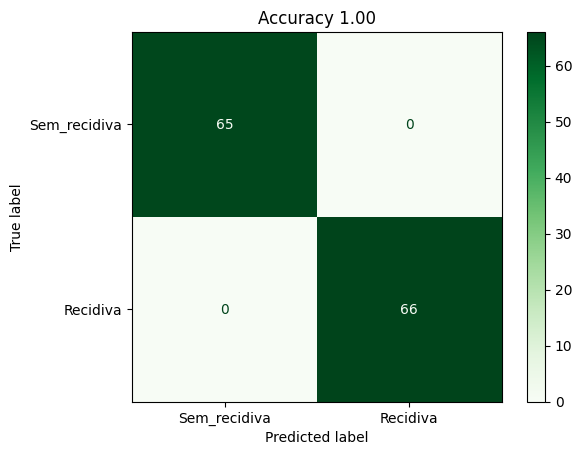


Classification Report:
              precision    recall  f1-score   support

    Recidiva       1.00      1.00      1.00        65
Sem_recidiva       1.00      1.00      1.00        66

    accuracy                           1.00       131
   macro avg       1.00      1.00      1.00       131
weighted avg       1.00      1.00      1.00       131

Total de variáveis originais pré-processadas: 35
Total de variáveis após VarianceThreshold:    34
Total de variáveis selecionadas no modelo:    34

--- Lista das Variáveis Selecionadas ---
1. num__GSTP1_AA
2. num__GSTP1_AG
3. num__GSTP1_GG
4. num__MGMT_AA
5. num__MGMT_AG
6. num__MGMT_GG
7. num__VDR_CC
8. num__VDR_TC
9. num__BCL2_AA
10. num__BCL2_CA
11. num__BCL2_CC
12. num__CASP9_AA
13. num__CASP9_GA
14. num__CASP9_GG
15. num__NKX3_CC
16. num__NKX3_TC
17. num__NKX3_TT
18. num__CASP3_CC
19. num__CASP3_CT
20. num__CASP3_TT
21. num__PTEN_CC
22. num__PTEN_CG
23. num__PTEN_GG
24. num__AKT1_CC
25. num__AKT1_CG
26. num__PI3K_AA
27. num__PI3K_GA
28.

In [28]:
# Instancia o classificador com o conjunto de treino
classificador = Classifier(df=df_train)

# Dicionários para guardar as métricas e as predições de cada algoritmo
metricas_train, pred_train = {}, {}

# k-NN: busca o melhor nº de vizinhos, pesos e métrica de distância
metricas_train["knn"], pred_train["knn"] = classificador.classify(modelo="knn")

--- Treinando modelo com Pipeline de pré-processamento ---

--- Melhores Resultados do Grid Search ---
Melhores hiperparâmetros: {'feature_selection__k': 'all', 'svm__C': 100, 'svm__gamma': 0.01, 'svm__kernel': 'rbf', 'var_threshold__threshold': 0.0001}
Melhor acurácia (CV): 0.5486

--- Desempenho no Conjunto de Teste ---
Acurácia final: 1.0000



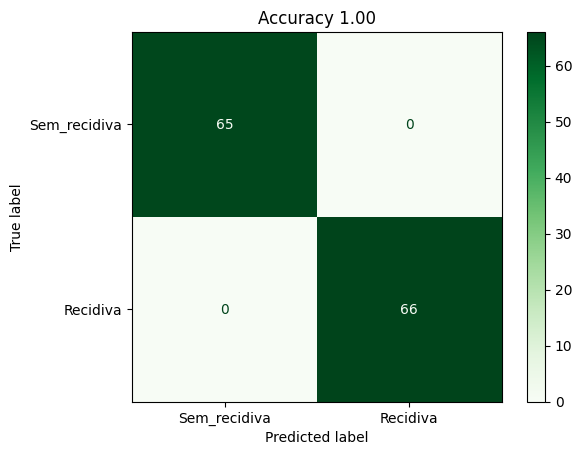


Classification Report:
              precision    recall  f1-score   support

    Recidiva       1.00      1.00      1.00        65
Sem_recidiva       1.00      1.00      1.00        66

    accuracy                           1.00       131
   macro avg       1.00      1.00      1.00       131
weighted avg       1.00      1.00      1.00       131

Total de variáveis originais pré-processadas: 35
Total de variáveis após VarianceThreshold:    34
Total de variáveis selecionadas no modelo:    34

--- Lista das Variáveis Selecionadas ---
1. num__GSTP1_AA
2. num__GSTP1_AG
3. num__GSTP1_GG
4. num__MGMT_AA
5. num__MGMT_AG
6. num__MGMT_GG
7. num__VDR_CC
8. num__VDR_TC
9. num__BCL2_AA
10. num__BCL2_CA
11. num__BCL2_CC
12. num__CASP9_AA
13. num__CASP9_GA
14. num__CASP9_GG
15. num__NKX3_CC
16. num__NKX3_TC
17. num__NKX3_TT
18. num__CASP3_CC
19. num__CASP3_CT
20. num__CASP3_TT
21. num__PTEN_CC
22. num__PTEN_CG
23. num__PTEN_GG
24. num__AKT1_CC
25. num__AKT1_CG
26. num__PI3K_AA
27. num__PI3K_GA
28.

In [29]:
# SVM: busca o melhor C (regularização), kernel (linear/rbf) e gamma
metricas_train["svm"], pred_train["svm"] = classificador.classify(modelo="svm")

--- Treinando modelo com Pipeline de pré-processamento ---

--- Melhores Resultados do Grid Search ---
Melhores hiperparâmetros: {'feature_selection__k': 'all', 'rf__criterion': 'gini', 'rf__max_depth': 10, 'rf__min_samples_split': 2, 'rf__n_estimators': 100, 'var_threshold__threshold': 0.0001}
Melhor acurácia (CV): 0.5266

--- Desempenho no Conjunto de Teste ---
Acurácia final: 1.0000



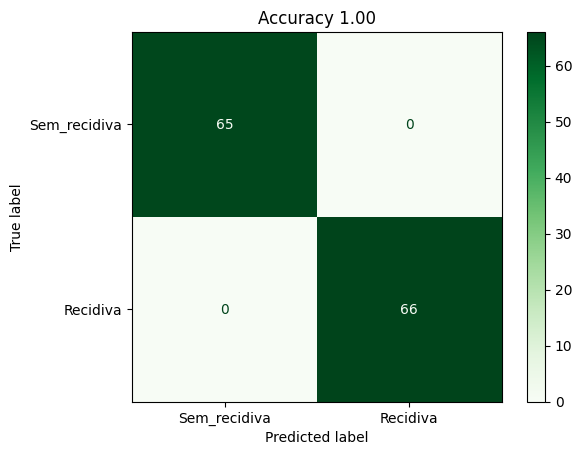


Classification Report:
              precision    recall  f1-score   support

    Recidiva       1.00      1.00      1.00        65
Sem_recidiva       1.00      1.00      1.00        66

    accuracy                           1.00       131
   macro avg       1.00      1.00      1.00       131
weighted avg       1.00      1.00      1.00       131

Total de variáveis originais pré-processadas: 35
Total de variáveis após VarianceThreshold:    34
Total de variáveis selecionadas no modelo:    34

--- Lista das Variáveis Selecionadas ---
1. num__GSTP1_AA
2. num__GSTP1_AG
3. num__GSTP1_GG
4. num__MGMT_AA
5. num__MGMT_AG
6. num__MGMT_GG
7. num__VDR_CC
8. num__VDR_TC
9. num__BCL2_AA
10. num__BCL2_CA
11. num__BCL2_CC
12. num__CASP9_AA
13. num__CASP9_GA
14. num__CASP9_GG
15. num__NKX3_CC
16. num__NKX3_TC
17. num__NKX3_TT
18. num__CASP3_CC
19. num__CASP3_CT
20. num__CASP3_TT
21. num__PTEN_CC
22. num__PTEN_CG
23. num__PTEN_GG
24. num__AKT1_CC
25. num__AKT1_CG
26. num__PI3K_AA
27. num__PI3K_GA
28.

In [30]:
# Random Forest: nº de árvores, profundidade, min_samples_split e critério
metricas_train["rf"], pred_train["rf"] = classificador.classify(modelo="rf")

--- Treinando modelo com Pipeline de pré-processamento ---

--- Melhores Resultados do Grid Search ---
Melhores hiperparâmetros: {'feature_selection__k': 'all', 'gb__learning_rate': 0.2, 'gb__max_depth': 5, 'gb__n_estimators': 50, 'gb__subsample': 0.8, 'var_threshold__threshold': 0.0001}
Melhor acurácia (CV): 0.5867

--- Desempenho no Conjunto de Teste ---
Acurácia final: 1.0000



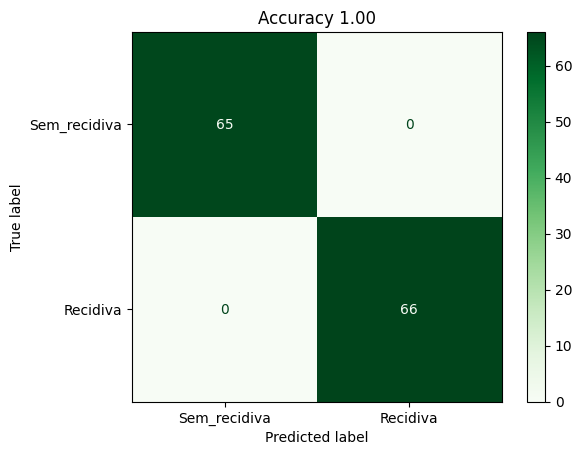


Classification Report:
              precision    recall  f1-score   support

    Recidiva       1.00      1.00      1.00        65
Sem_recidiva       1.00      1.00      1.00        66

    accuracy                           1.00       131
   macro avg       1.00      1.00      1.00       131
weighted avg       1.00      1.00      1.00       131

Total de variáveis originais pré-processadas: 35
Total de variáveis após VarianceThreshold:    34
Total de variáveis selecionadas no modelo:    34

--- Lista das Variáveis Selecionadas ---
1. num__GSTP1_AA
2. num__GSTP1_AG
3. num__GSTP1_GG
4. num__MGMT_AA
5. num__MGMT_AG
6. num__MGMT_GG
7. num__VDR_CC
8. num__VDR_TC
9. num__BCL2_AA
10. num__BCL2_CA
11. num__BCL2_CC
12. num__CASP9_AA
13. num__CASP9_GA
14. num__CASP9_GG
15. num__NKX3_CC
16. num__NKX3_TC
17. num__NKX3_TT
18. num__CASP3_CC
19. num__CASP3_CT
20. num__CASP3_TT
21. num__PTEN_CC
22. num__PTEN_CG
23. num__PTEN_GG
24. num__AKT1_CC
25. num__AKT1_CG
26. num__PI3K_AA
27. num__PI3K_GA
28.

In [31]:
# Gradient Boosting: nº de estágios, learning rate, profundidade e subsample
metricas_train["gbm"], pred_train["gbm"] = classificador.classify(modelo="gbm")

--- Treinando modelo com Pipeline de pré-processamento ---

--- Melhores Resultados do Grid Search ---
Melhores hiperparâmetros: {'feature_selection__k': 2, 'nb__var_smoothing': 1.0, 'var_threshold__threshold': 0.0001}
Melhor acurácia (CV): 0.4730

--- Desempenho no Conjunto de Teste ---
Acurácia final: 0.5191



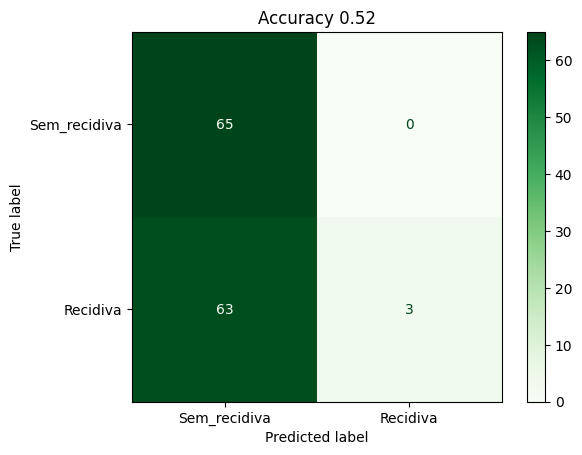


Classification Report:
              precision    recall  f1-score   support

    Recidiva       0.51      1.00      0.67        65
Sem_recidiva       1.00      0.05      0.09        66

    accuracy                           0.52       131
   macro avg       0.75      0.52      0.38       131
weighted avg       0.76      0.52      0.38       131

Total de variáveis originais pré-processadas: 35
Total de variáveis após VarianceThreshold:    34
Total de variáveis selecionadas no modelo:    2

--- Lista das Variáveis Selecionadas ---
1. num__AMACR_GG
2. num__MTOR_CT

--- Status de Cada Atributo no Pipeline ---
Atributo_Preprocessado  Passou_Variancia  Selecionado_Final
         num__GSTP1_AA              True              False
         num__GSTP1_AG              True              False
         num__GSTP1_GG              True              False
          num__MGMT_AA              True              False
          num__MGMT_AG              True              False
          num__MGMT_GG 

In [32]:
# Gaussian Naive Bayes: suavização da variância (var_smoothing)
metricas_train["nb"], pred_train["nb"] = classificador.classify(modelo="nb")

--- Treinando modelo com Pipeline de pré-processamento ---

--- Melhores Resultados do Grid Search ---
Melhores hiperparâmetros: {'feature_selection__k': 'all', 'mlp__activation': 'relu', 'mlp__alpha': 0.0001, 'mlp__hidden_layer_sizes': (10,), 'mlp__solver': 'lbfgs', 'var_threshold__threshold': 0.0001}
Melhor acurácia (CV): 0.6024

--- Desempenho no Conjunto de Teste ---
Acurácia final: 1.0000



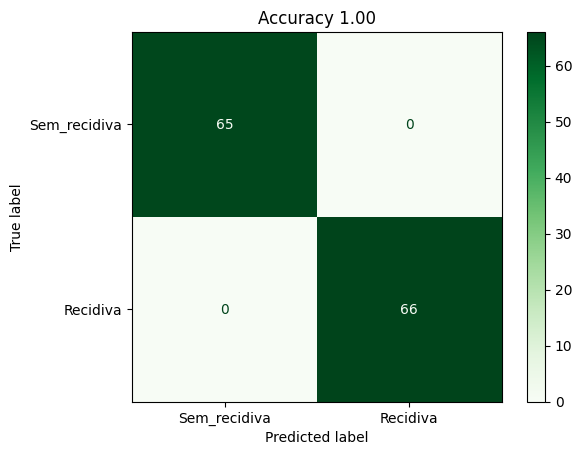


Classification Report:
              precision    recall  f1-score   support

    Recidiva       1.00      1.00      1.00        65
Sem_recidiva       1.00      1.00      1.00        66

    accuracy                           1.00       131
   macro avg       1.00      1.00      1.00       131
weighted avg       1.00      1.00      1.00       131

Total de variáveis originais pré-processadas: 35
Total de variáveis após VarianceThreshold:    34
Total de variáveis selecionadas no modelo:    34

--- Lista das Variáveis Selecionadas ---
1. num__GSTP1_AA
2. num__GSTP1_AG
3. num__GSTP1_GG
4. num__MGMT_AA
5. num__MGMT_AG
6. num__MGMT_GG
7. num__VDR_CC
8. num__VDR_TC
9. num__BCL2_AA
10. num__BCL2_CA
11. num__BCL2_CC
12. num__CASP9_AA
13. num__CASP9_GA
14. num__CASP9_GG
15. num__NKX3_CC
16. num__NKX3_TC
17. num__NKX3_TT
18. num__CASP3_CC
19. num__CASP3_CT
20. num__CASP3_TT
21. num__PTEN_CC
22. num__PTEN_CG
23. num__PTEN_GG
24. num__AKT1_CC
25. num__AKT1_CG
26. num__PI3K_AA
27. num__PI3K_GA
28.

In [33]:
# Rede Neural (MLP): arquitetura, função de ativação, otimizador e alpha (L2)
metricas_train["nn"], pred_train["nn"] = classificador.classify(modelo="nn")

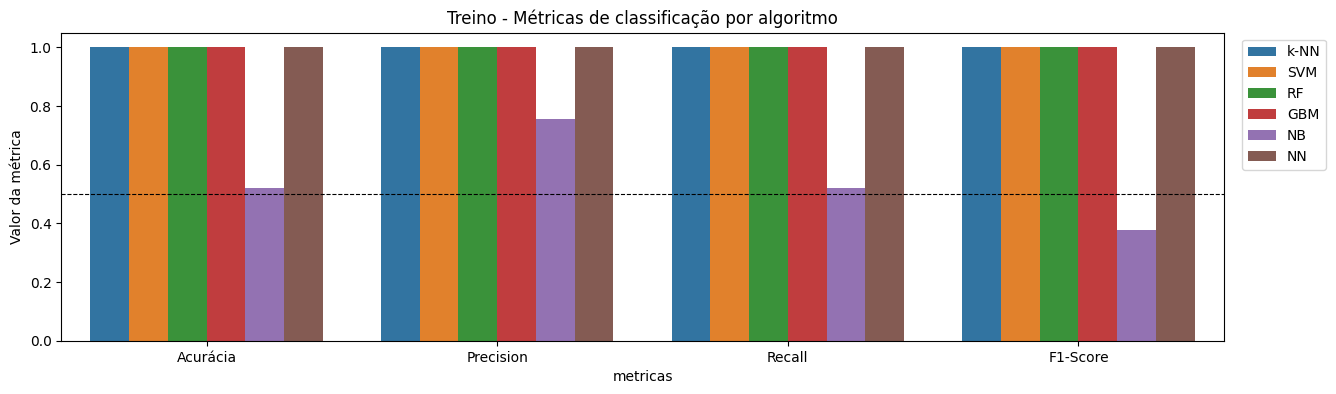

,classe,k-NN,SVM,RF,GBM,NB,NN
0,Recidiva,Recidiva,Recidiva,Recidiva,Recidiva,Recidiva,Recidiva
1,Recidiva,Recidiva,Recidiva,Recidiva,Recidiva,Recidiva,Recidiva
2,Recidiva,Recidiva,Recidiva,Recidiva,Recidiva,Recidiva,Recidiva
3,Recidiva,Recidiva,Recidiva,Recidiva,Recidiva,Recidiva,Recidiva
4,Recidiva,Recidiva,Recidiva,Recidiva,Recidiva,Recidiva,Recidiva


In [34]:
# Organizando as métricas de treino e plotando
df_metricas_train = organizar_metricas(metricas_train)
plotar_metricas(df_metricas_train, "Treino - Métricas de classificação por algoritmo")

# Guardamos as predições em uma cópia, para não misturar com as features
df_pred_train = df_train.copy()
for modelo, nome in MODELOS.items():
    df_pred_train[nome] = pred_train[modelo]
df_pred_train[["classe", *MODELOS.values()]].head()

### 2.2 Validação

Mesmo procedimento no conjunto de validação (em um laço, para deixar o notebook mais enxuto).

 VALIDAÇÃO - k-NN
--- Treinando modelo com Pipeline de pré-processamento ---

--- Melhores Resultados do Grid Search ---
Melhores hiperparâmetros: {'feature_selection__k': 'all', 'knn__metric': 'euclidean', 'knn__n_neighbors': 1, 'knn__weights': 'uniform', 'var_threshold__threshold': 0.0001}
Melhor acurácia (CV): 0.5667

--- Desempenho no Conjunto de Teste ---
Acurácia final: 1.0000



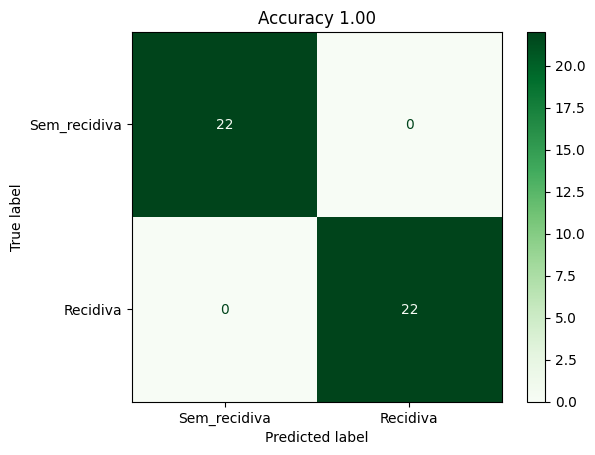


Classification Report:
              precision    recall  f1-score   support

    Recidiva       1.00      1.00      1.00        22
Sem_recidiva       1.00      1.00      1.00        22

    accuracy                           1.00        44
   macro avg       1.00      1.00      1.00        44
weighted avg       1.00      1.00      1.00        44

Total de variáveis originais pré-processadas: 35
Total de variáveis após VarianceThreshold:    32
Total de variáveis selecionadas no modelo:    32

--- Lista das Variáveis Selecionadas ---
1. num__GSTP1_AA
2. num__GSTP1_AG
3. num__GSTP1_GG
4. num__MGMT_AA
5. num__MGMT_AG
6. num__VDR_CC
7. num__VDR_TC
8. num__BCL2_AA
9. num__BCL2_CA
10. num__BCL2_CC
11. num__CASP9_AA
12. num__CASP9_GA
13. num__CASP9_GG
14. num__NKX3_CC
15. num__NKX3_TC
16. num__NKX3_TT
17. num__CASP3_CC
18. num__CASP3_CT
19. num__PTEN_CC
20. num__PTEN_CG
21. num__PTEN_GG
22. num__AKT1_CC
23. num__AKT1_CG
24. num__PI3K_AA
25. num__PI3K_GA
26. num__PI3K_GG
27. num__AMACR_AA
28.

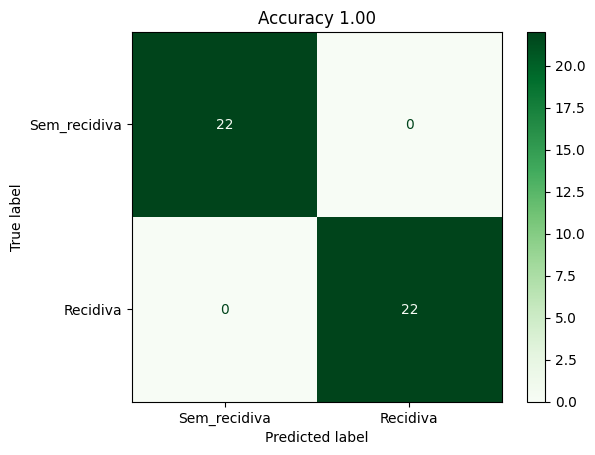


Classification Report:
              precision    recall  f1-score   support

    Recidiva       1.00      1.00      1.00        22
Sem_recidiva       1.00      1.00      1.00        22

    accuracy                           1.00        44
   macro avg       1.00      1.00      1.00        44
weighted avg       1.00      1.00      1.00        44

Total de variáveis originais pré-processadas: 35
Total de variáveis após VarianceThreshold:    32
Total de variáveis selecionadas no modelo:    32

--- Lista das Variáveis Selecionadas ---
1. num__GSTP1_AA
2. num__GSTP1_AG
3. num__GSTP1_GG
4. num__MGMT_AA
5. num__MGMT_AG
6. num__VDR_CC
7. num__VDR_TC
8. num__BCL2_AA
9. num__BCL2_CA
10. num__BCL2_CC
11. num__CASP9_AA
12. num__CASP9_GA
13. num__CASP9_GG
14. num__NKX3_CC
15. num__NKX3_TC
16. num__NKX3_TT
17. num__CASP3_CC
18. num__CASP3_CT
19. num__PTEN_CC
20. num__PTEN_CG
21. num__PTEN_GG
22. num__AKT1_CC
23. num__AKT1_CG
24. num__PI3K_AA
25. num__PI3K_GA
26. num__PI3K_GG
27. num__AMACR_AA
28.

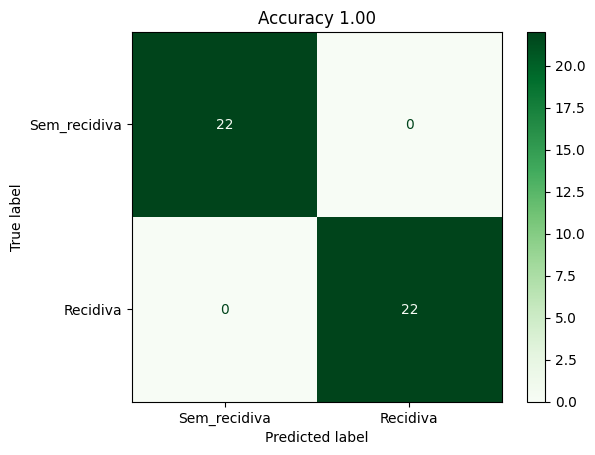


Classification Report:
              precision    recall  f1-score   support

    Recidiva       1.00      1.00      1.00        22
Sem_recidiva       1.00      1.00      1.00        22

    accuracy                           1.00        44
   macro avg       1.00      1.00      1.00        44
weighted avg       1.00      1.00      1.00        44

Total de variáveis originais pré-processadas: 35
Total de variáveis após VarianceThreshold:    32
Total de variáveis selecionadas no modelo:    32

--- Lista das Variáveis Selecionadas ---
1. num__GSTP1_AA
2. num__GSTP1_AG
3. num__GSTP1_GG
4. num__MGMT_AA
5. num__MGMT_AG
6. num__VDR_CC
7. num__VDR_TC
8. num__BCL2_AA
9. num__BCL2_CA
10. num__BCL2_CC
11. num__CASP9_AA
12. num__CASP9_GA
13. num__CASP9_GG
14. num__NKX3_CC
15. num__NKX3_TC
16. num__NKX3_TT
17. num__CASP3_CC
18. num__CASP3_CT
19. num__PTEN_CC
20. num__PTEN_CG
21. num__PTEN_GG
22. num__AKT1_CC
23. num__AKT1_CG
24. num__PI3K_AA
25. num__PI3K_GA
26. num__PI3K_GG
27. num__AMACR_AA
28.

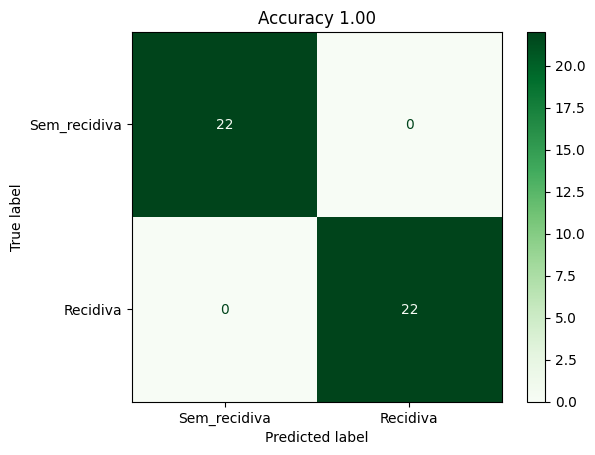


Classification Report:
              precision    recall  f1-score   support

    Recidiva       1.00      1.00      1.00        22
Sem_recidiva       1.00      1.00      1.00        22

    accuracy                           1.00        44
   macro avg       1.00      1.00      1.00        44
weighted avg       1.00      1.00      1.00        44

Total de variáveis originais pré-processadas: 35
Total de variáveis após VarianceThreshold:    32
Total de variáveis selecionadas no modelo:    32

--- Lista das Variáveis Selecionadas ---
1. num__GSTP1_AA
2. num__GSTP1_AG
3. num__GSTP1_GG
4. num__MGMT_AA
5. num__MGMT_AG
6. num__VDR_CC
7. num__VDR_TC
8. num__BCL2_AA
9. num__BCL2_CA
10. num__BCL2_CC
11. num__CASP9_AA
12. num__CASP9_GA
13. num__CASP9_GG
14. num__NKX3_CC
15. num__NKX3_TC
16. num__NKX3_TT
17. num__CASP3_CC
18. num__CASP3_CT
19. num__PTEN_CC
20. num__PTEN_CG
21. num__PTEN_GG
22. num__AKT1_CC
23. num__AKT1_CG
24. num__PI3K_AA
25. num__PI3K_GA
26. num__PI3K_GG
27. num__AMACR_AA
28.

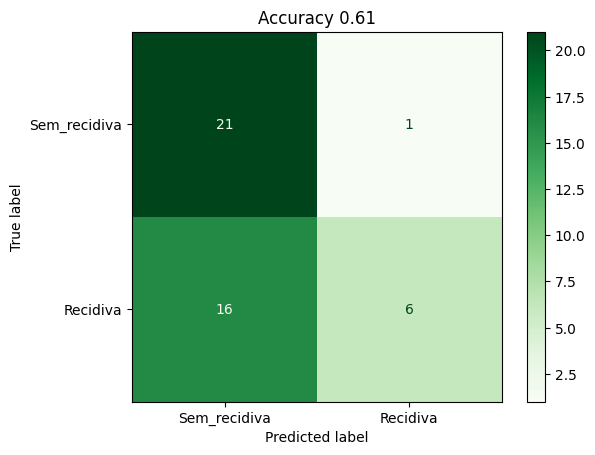


Classification Report:
              precision    recall  f1-score   support

    Recidiva       0.57      0.95      0.71        22
Sem_recidiva       0.86      0.27      0.41        22

    accuracy                           0.61        44
   macro avg       0.71      0.61      0.56        44
weighted avg       0.71      0.61      0.56        44

Total de variáveis originais pré-processadas: 35
Total de variáveis após VarianceThreshold:    32
Total de variáveis selecionadas no modelo:    32

--- Lista das Variáveis Selecionadas ---
1. num__GSTP1_AA
2. num__GSTP1_AG
3. num__GSTP1_GG
4. num__MGMT_AA
5. num__MGMT_AG
6. num__VDR_CC
7. num__VDR_TC
8. num__BCL2_AA
9. num__BCL2_CA
10. num__BCL2_CC
11. num__CASP9_AA
12. num__CASP9_GA
13. num__CASP9_GG
14. num__NKX3_CC
15. num__NKX3_TC
16. num__NKX3_TT
17. num__CASP3_CC
18. num__CASP3_CT
19. num__PTEN_CC
20. num__PTEN_CG
21. num__PTEN_GG
22. num__AKT1_CC
23. num__AKT1_CG
24. num__PI3K_AA
25. num__PI3K_GA
26. num__PI3K_GG
27. num__AMACR_AA
28.

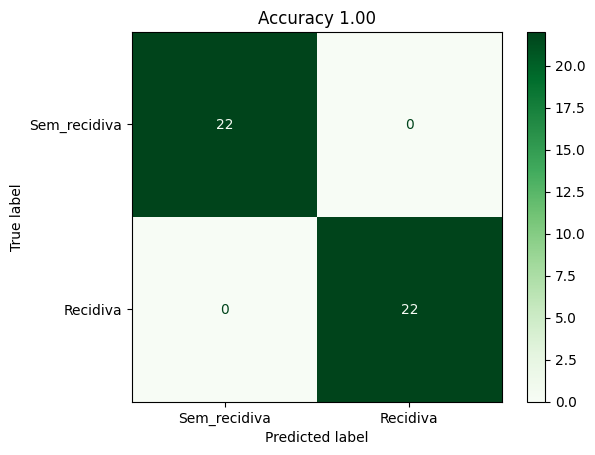


Classification Report:
              precision    recall  f1-score   support

    Recidiva       1.00      1.00      1.00        22
Sem_recidiva       1.00      1.00      1.00        22

    accuracy                           1.00        44
   macro avg       1.00      1.00      1.00        44
weighted avg       1.00      1.00      1.00        44

Total de variáveis originais pré-processadas: 35
Total de variáveis após VarianceThreshold:    32
Total de variáveis selecionadas no modelo:    32

--- Lista das Variáveis Selecionadas ---
1. num__GSTP1_AA
2. num__GSTP1_AG
3. num__GSTP1_GG
4. num__MGMT_AA
5. num__MGMT_AG
6. num__VDR_CC
7. num__VDR_TC
8. num__BCL2_AA
9. num__BCL2_CA
10. num__BCL2_CC
11. num__CASP9_AA
12. num__CASP9_GA
13. num__CASP9_GG
14. num__NKX3_CC
15. num__NKX3_TC
16. num__NKX3_TT
17. num__CASP3_CC
18. num__CASP3_CT
19. num__PTEN_CC
20. num__PTEN_CG
21. num__PTEN_GG
22. num__AKT1_CC
23. num__AKT1_CG
24. num__PI3K_AA
25. num__PI3K_GA
26. num__PI3K_GG
27. num__AMACR_AA
28.

In [35]:
classificador = Classifier(df=df_valid)
metricas_valid, pred_valid = {}, {}

for modelo, nome in MODELOS.items():
    print("=" * 70)
    print(f" VALIDAÇÃO - {nome}")
    print("=" * 70)
    metricas_valid[modelo], pred_valid[modelo] = classificador.classify(modelo=modelo)

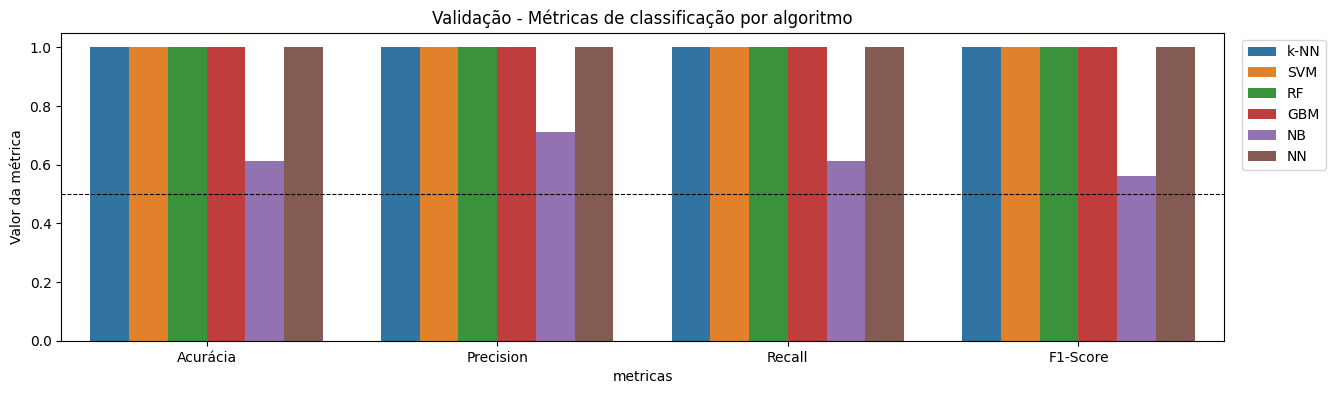

,classe,k-NN,SVM,RF,GBM,NB,NN
0,Sem_recidiva,Sem_recidiva,Sem_recidiva,Sem_recidiva,Sem_recidiva,Recidiva,Sem_recidiva
1,Sem_recidiva,Sem_recidiva,Sem_recidiva,Sem_recidiva,Sem_recidiva,Sem_recidiva,Sem_recidiva
2,Recidiva,Recidiva,Recidiva,Recidiva,Recidiva,Recidiva,Recidiva
3,Recidiva,Recidiva,Recidiva,Recidiva,Recidiva,Recidiva,Recidiva
4,Sem_recidiva,Sem_recidiva,Sem_recidiva,Sem_recidiva,Sem_recidiva,Recidiva,Sem_recidiva


In [36]:
df_metricas_valid = organizar_metricas(metricas_valid)
plotar_metricas(df_metricas_valid, "Validação - Métricas de classificação por algoritmo")

df_pred_valid = df_valid.copy()
for modelo, nome in MODELOS.items():
    df_pred_valid[nome] = pred_valid[modelo]
df_pred_valid[["classe", *MODELOS.values()]].head()

### 2.3 Teste

 TESTE - k-NN
--- Treinando modelo com Pipeline de pré-processamento ---

--- Melhores Resultados do Grid Search ---
Melhores hiperparâmetros: {'feature_selection__k': 'all', 'knn__metric': 'manhattan', 'knn__n_neighbors': 3, 'knn__weights': 'distance', 'var_threshold__threshold': 0.0001}
Melhor acurácia (CV): 0.6365

--- Desempenho no Conjunto de Teste ---
Acurácia final: 1.0000



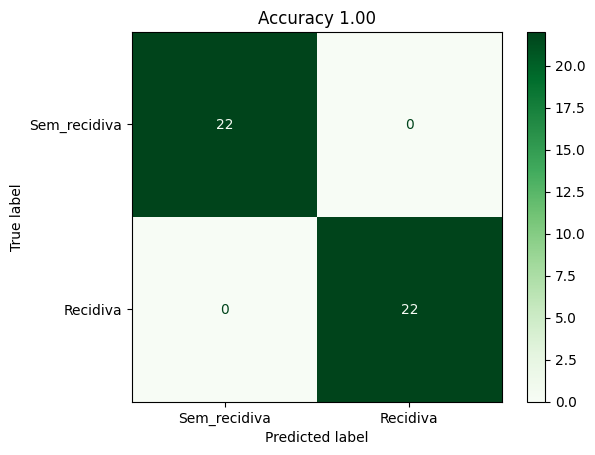


Classification Report:
              precision    recall  f1-score   support

    Recidiva       1.00      1.00      1.00        22
Sem_recidiva       1.00      1.00      1.00        22

    accuracy                           1.00        44
   macro avg       1.00      1.00      1.00        44
weighted avg       1.00      1.00      1.00        44

Total de variáveis originais pré-processadas: 35
Total de variáveis após VarianceThreshold:    34
Total de variáveis selecionadas no modelo:    34

--- Lista das Variáveis Selecionadas ---
1. num__GSTP1_AA
2. num__GSTP1_AG
3. num__GSTP1_GG
4. num__MGMT_AA
5. num__MGMT_AG
6. num__MGMT_GG
7. num__VDR_CC
8. num__VDR_TC
9. num__BCL2_AA
10. num__BCL2_CA
11. num__BCL2_CC
12. num__CASP9_AA
13. num__CASP9_GA
14. num__CASP9_GG
15. num__NKX3_CC
16. num__NKX3_TC
17. num__NKX3_TT
18. num__CASP3_CC
19. num__CASP3_CT
20. num__PTEN_CC
21. num__PTEN_CG
22. num__PTEN_GG
23. num__AKT1_CC
24. num__AKT1_CG
25. num__AKT1_GG
26. num__PI3K_AA
27. num__PI3K_GA
28. 

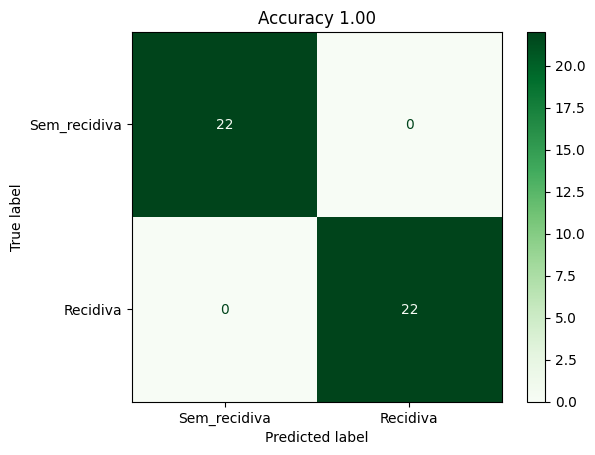


Classification Report:
              precision    recall  f1-score   support

    Recidiva       1.00      1.00      1.00        22
Sem_recidiva       1.00      1.00      1.00        22

    accuracy                           1.00        44
   macro avg       1.00      1.00      1.00        44
weighted avg       1.00      1.00      1.00        44

Total de variáveis originais pré-processadas: 35
Total de variáveis após VarianceThreshold:    34
Total de variáveis selecionadas no modelo:    34

--- Lista das Variáveis Selecionadas ---
1. num__GSTP1_AA
2. num__GSTP1_AG
3. num__GSTP1_GG
4. num__MGMT_AA
5. num__MGMT_AG
6. num__MGMT_GG
7. num__VDR_CC
8. num__VDR_TC
9. num__BCL2_AA
10. num__BCL2_CA
11. num__BCL2_CC
12. num__CASP9_AA
13. num__CASP9_GA
14. num__CASP9_GG
15. num__NKX3_CC
16. num__NKX3_TC
17. num__NKX3_TT
18. num__CASP3_CC
19. num__CASP3_CT
20. num__PTEN_CC
21. num__PTEN_CG
22. num__PTEN_GG
23. num__AKT1_CC
24. num__AKT1_CG
25. num__AKT1_GG
26. num__PI3K_AA
27. num__PI3K_GA
28. 

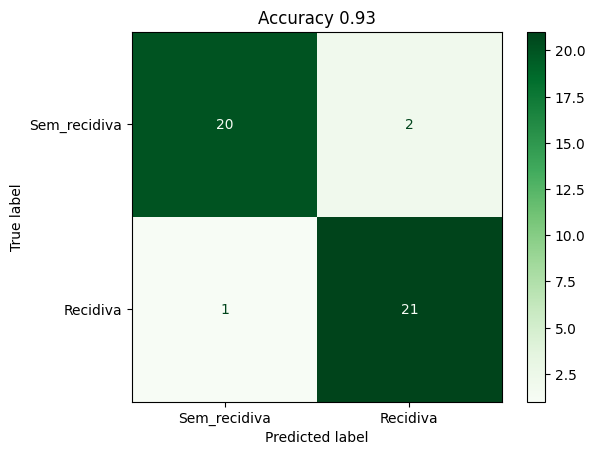


Classification Report:
              precision    recall  f1-score   support

    Recidiva       0.95      0.91      0.93        22
Sem_recidiva       0.91      0.95      0.93        22

    accuracy                           0.93        44
   macro avg       0.93      0.93      0.93        44
weighted avg       0.93      0.93      0.93        44

Total de variáveis originais pré-processadas: 35
Total de variáveis após VarianceThreshold:    34
Total de variáveis selecionadas no modelo:    34

--- Lista das Variáveis Selecionadas ---
1. num__GSTP1_AA
2. num__GSTP1_AG
3. num__GSTP1_GG
4. num__MGMT_AA
5. num__MGMT_AG
6. num__MGMT_GG
7. num__VDR_CC
8. num__VDR_TC
9. num__BCL2_AA
10. num__BCL2_CA
11. num__BCL2_CC
12. num__CASP9_AA
13. num__CASP9_GA
14. num__CASP9_GG
15. num__NKX3_CC
16. num__NKX3_TC
17. num__NKX3_TT
18. num__CASP3_CC
19. num__CASP3_CT
20. num__PTEN_CC
21. num__PTEN_CG
22. num__PTEN_GG
23. num__AKT1_CC
24. num__AKT1_CG
25. num__AKT1_GG
26. num__PI3K_AA
27. num__PI3K_GA
28. 

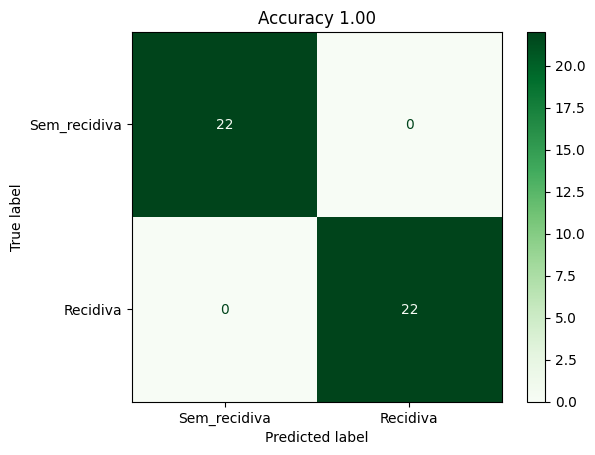


Classification Report:
              precision    recall  f1-score   support

    Recidiva       1.00      1.00      1.00        22
Sem_recidiva       1.00      1.00      1.00        22

    accuracy                           1.00        44
   macro avg       1.00      1.00      1.00        44
weighted avg       1.00      1.00      1.00        44

Total de variáveis originais pré-processadas: 35
Total de variáveis após VarianceThreshold:    34
Total de variáveis selecionadas no modelo:    34

--- Lista das Variáveis Selecionadas ---
1. num__GSTP1_AA
2. num__GSTP1_AG
3. num__GSTP1_GG
4. num__MGMT_AA
5. num__MGMT_AG
6. num__MGMT_GG
7. num__VDR_CC
8. num__VDR_TC
9. num__BCL2_AA
10. num__BCL2_CA
11. num__BCL2_CC
12. num__CASP9_AA
13. num__CASP9_GA
14. num__CASP9_GG
15. num__NKX3_CC
16. num__NKX3_TC
17. num__NKX3_TT
18. num__CASP3_CC
19. num__CASP3_CT
20. num__PTEN_CC
21. num__PTEN_CG
22. num__PTEN_GG
23. num__AKT1_CC
24. num__AKT1_CG
25. num__AKT1_GG
26. num__PI3K_AA
27. num__PI3K_GA
28. 

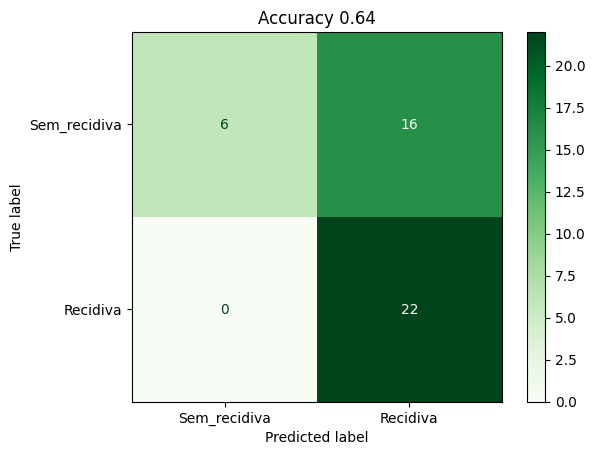


Classification Report:
              precision    recall  f1-score   support

    Recidiva       1.00      0.27      0.43        22
Sem_recidiva       0.58      1.00      0.73        22

    accuracy                           0.64        44
   macro avg       0.79      0.64      0.58        44
weighted avg       0.79      0.64      0.58        44

Total de variáveis originais pré-processadas: 35
Total de variáveis após VarianceThreshold:    34
Total de variáveis selecionadas no modelo:    34

--- Lista das Variáveis Selecionadas ---
1. num__GSTP1_AA
2. num__GSTP1_AG
3. num__GSTP1_GG
4. num__MGMT_AA
5. num__MGMT_AG
6. num__MGMT_GG
7. num__VDR_CC
8. num__VDR_TC
9. num__BCL2_AA
10. num__BCL2_CA
11. num__BCL2_CC
12. num__CASP9_AA
13. num__CASP9_GA
14. num__CASP9_GG
15. num__NKX3_CC
16. num__NKX3_TC
17. num__NKX3_TT
18. num__CASP3_CC
19. num__CASP3_CT
20. num__PTEN_CC
21. num__PTEN_CG
22. num__PTEN_GG
23. num__AKT1_CC
24. num__AKT1_CG
25. num__AKT1_GG
26. num__PI3K_AA
27. num__PI3K_GA
28. 

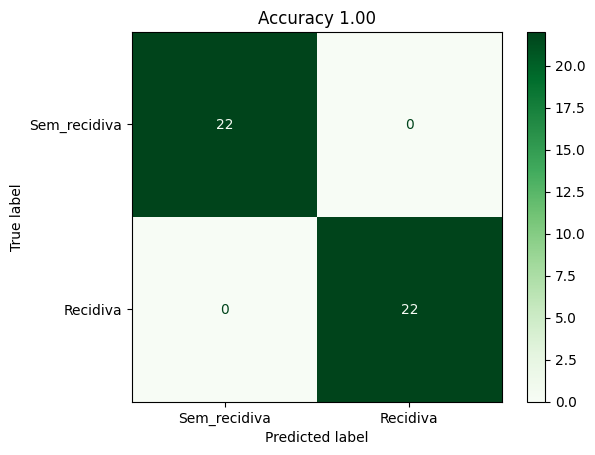


Classification Report:
              precision    recall  f1-score   support

    Recidiva       1.00      1.00      1.00        22
Sem_recidiva       1.00      1.00      1.00        22

    accuracy                           1.00        44
   macro avg       1.00      1.00      1.00        44
weighted avg       1.00      1.00      1.00        44

Total de variáveis originais pré-processadas: 35
Total de variáveis após VarianceThreshold:    34
Total de variáveis selecionadas no modelo:    34

--- Lista das Variáveis Selecionadas ---
1. num__GSTP1_AA
2. num__GSTP1_AG
3. num__GSTP1_GG
4. num__MGMT_AA
5. num__MGMT_AG
6. num__MGMT_GG
7. num__VDR_CC
8. num__VDR_TC
9. num__BCL2_AA
10. num__BCL2_CA
11. num__BCL2_CC
12. num__CASP9_AA
13. num__CASP9_GA
14. num__CASP9_GG
15. num__NKX3_CC
16. num__NKX3_TC
17. num__NKX3_TT
18. num__CASP3_CC
19. num__CASP3_CT
20. num__PTEN_CC
21. num__PTEN_CG
22. num__PTEN_GG
23. num__AKT1_CC
24. num__AKT1_CG
25. num__AKT1_GG
26. num__PI3K_AA
27. num__PI3K_GA
28. 

In [37]:
classificador = Classifier(df=df_test)
metricas_test, pred_test = {}, {}

for modelo, nome in MODELOS.items():
    print("=" * 70)
    print(f" TESTE - {nome}")
    print("=" * 70)
    metricas_test[modelo], pred_test[modelo] = classificador.classify(modelo=modelo)

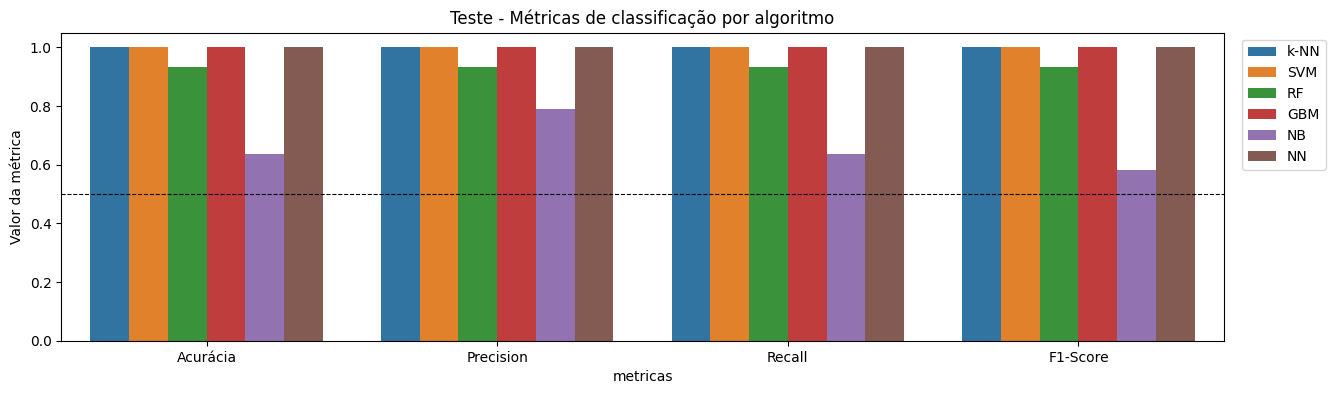

,classe,k-NN,SVM,RF,GBM,NB,NN
0,Sem_recidiva,Sem_recidiva,Sem_recidiva,Sem_recidiva,Sem_recidiva,Sem_recidiva,Sem_recidiva
1,Sem_recidiva,Sem_recidiva,Sem_recidiva,Sem_recidiva,Sem_recidiva,Sem_recidiva,Sem_recidiva
2,Sem_recidiva,Sem_recidiva,Sem_recidiva,Sem_recidiva,Sem_recidiva,Sem_recidiva,Sem_recidiva
3,Recidiva,Recidiva,Recidiva,Sem_recidiva,Recidiva,Sem_recidiva,Recidiva
4,Sem_recidiva,Sem_recidiva,Sem_recidiva,Sem_recidiva,Sem_recidiva,Sem_recidiva,Sem_recidiva


In [38]:
df_metricas_test = organizar_metricas(metricas_test)
plotar_metricas(df_metricas_test, "Teste - Métricas de classificação por algoritmo")

df_pred_test = df_test.copy()
for modelo, nome in MODELOS.items():
    df_pred_test[nome] = pred_test[modelo]
df_pred_test[["classe", *MODELOS.values()]].head()

---
## 3. Comparação dos Algoritmos (padrão da aula)

Juntamos as métricas dos três conjuntos. Um modelo consistente apresenta valores parecidos em treino, validação e teste.

 COMPARAÇÃO DOS ALGORITMOS DE CLASSIFICAÇÃO (Classifier.classify)


conjunto   Treino                            Validação                     \
metricas Acurácia F1-Score Precision  Recall  Acurácia F1-Score Precision   
modelo                                                                      
GBM        1.0000    1.000    1.0000  1.0000    1.0000   1.0000    1.0000   
NB         0.5191    0.378    0.7558  0.5191    0.6136   0.5628    0.7124   
NN         1.0000    1.000    1.0000  1.0000    1.0000   1.0000    1.0000   
RF         1.0000    1.000    1.0000  1.0000    1.0000   1.0000    1.0000   
SVM        1.0000    1.000    1.0000  1.0000    1.0000   1.0000    1.0000   
k-NN       1.0000    1.000    1.0000  1.0000    1.0000   1.0000    1.0000   

conjunto            Teste                             
metricas  Recall Acurácia F1-Score Precision  Recall  
modelo                                                
GBM       1.0000   1.0000   1.0000    1.0000  1.0000  
NB        0.6136   0.6364   0.5810    0.7895  0.6364  
NN        1.0000   1.0000   1.0000    1.0000  1.0000  
RF        1.0000   0.9318   0.9318    0.9327  0.9318  
SVM       1.0000   1.0000   1.0000    1.0000  1.0000  
k-NN      1.0000   1.0000   1.0000    1.0000  1.0000

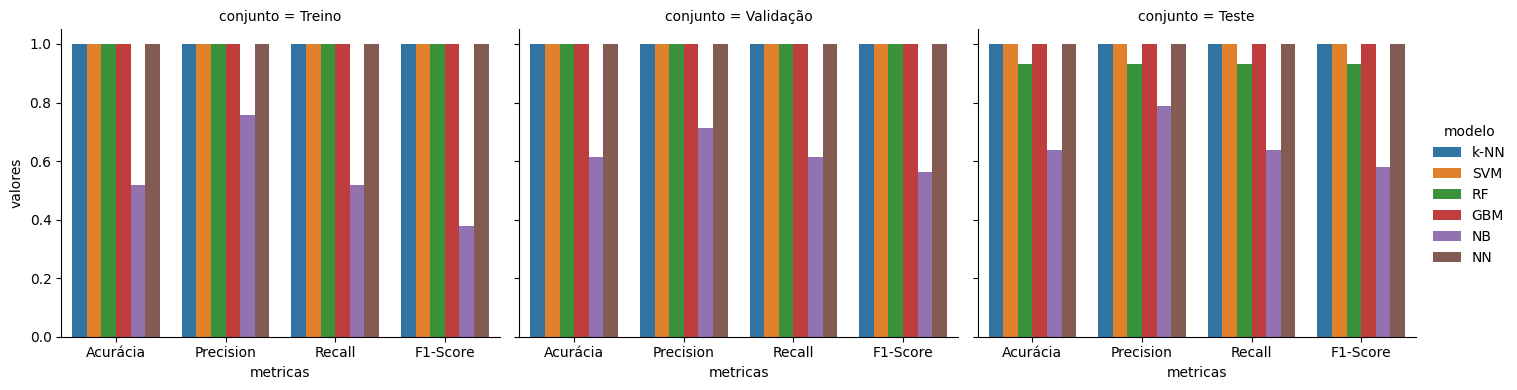


Guia de interpretação (todas: quanto MAIOR melhor, de 0 a 1):
  Acurácia:  proporção de acertos totais
  Precision: dos pacientes previstos em uma classe, quantos realmente são dela
  Recall:    dos pacientes de uma classe, quantos o modelo encontrou
  F1-Score:  média harmônica entre Precision e Recall
  (no Classifier as métricas são 'weighted' = média ponderada entre as classes)


In [39]:
# Identifica de qual conjunto veio cada métrica
df_metricas_train["conjunto"] = "Treino"
df_metricas_valid["conjunto"] = "Validação"
df_metricas_test["conjunto"] = "Teste"

df_comparacao = pd.concat(
    [df_metricas_train, df_metricas_valid, df_metricas_test], ignore_index=True
)

# Tabela resumo: linhas = algoritmos, colunas = conjunto x métrica
tabela_comparacao = df_comparacao.pivot_table(
    index="modelo", columns=["conjunto", "metricas"], values="valores"
).reindex(columns=["Treino", "Validação", "Teste"], level=0)

print("=" * 70)
print(" COMPARAÇÃO DOS ALGORITMOS DE CLASSIFICAÇÃO (Classifier.classify)")
print("=" * 70)
display(tabela_comparacao.round(4))

# Gráfico: um painel por conjunto
sns.catplot(
    data=df_comparacao,
    x="metricas",
    y="valores",
    hue="modelo",
    col="conjunto",
    kind="bar",
    height=4,
    aspect=1.2,
)
plt.show()

print("\nGuia de interpretação (todas: quanto MAIOR melhor, de 0 a 1):")
print("  Acurácia:  proporção de acertos totais")
print("  Precision: dos pacientes previstos em uma classe, quantos realmente são dela")
print("  Recall:    dos pacientes de uma classe, quantos o modelo encontrou")
print("  F1-Score:  média harmônica entre Precision e Recall")
print("  (no Classifier as métricas são 'weighted' = média ponderada entre as classes)")

---
## 4. Teste Qui-Quadrado: distribuição das classes preditas (Treino x Teste)

Como na aula, verificamos se a distribuição das classes **preditas** pelo modelo é estatisticamente igual no treino e no teste.

- **H0:** a proporção de classes preditas é igual no treino e no teste (modelo estável)
- **H1:** as proporções são diferentes

Usamos os modelos da seção 4 (ajustados apenas no treino).

In [40]:
def testar_hipotese(df: pd.DataFrame) -> float:
    """
    Testa (Qui-Quadrado) se a distribuição das classes preditas no treino e
    no teste é estatisticamente igual (homogênea) ou diferente (heterogênea).

    Parâmetros:
        df : pd.DataFrame com as colunas 'Dataset' e 'Classe_Predita'.
    Retorna:
        p-valor do teste.
    """
    # Tabela de contingência (frequências observadas)
    tabela_contingencia = pd.crosstab(df["Dataset"], df["Classe_Predita"])
    print("Tabela de Contingência (Observada):")
    print(tabela_contingencia)
    print("-" * 40)

    # Teste Qui-Quadrado
    chi2, p_valor, graus_liberdade, _ = chi2_contingency(tabela_contingencia)
    print(f"Estatística Qui-Quadrado: {chi2:.4f}")
    print(f"Graus de Liberdade: {graus_liberdade}")
    print(f"Valor-p: {p_valor:.4f}")

    # Decisão com nível de significância de 5%
    alpha = 0.05
    if p_valor < alpha:
        print("Conclusão: Rejeitamos H0 -> distribuições ESTATISTICAMENTE DIFERENTES (heterogêneas).")
    else:
        print("Conclusão: Falhamos em rejeitar H0 -> distribuições ESTATISTICAMENTE IGUAIS (homogêneas).")
    return p_valor


resultados_chi2 = []
for modelo, nome in MODELOS.items():
    df_hip = pd.DataFrame(
        {
            "Dataset": ["Treino"] * len(df_pred_train) + ["Teste"] * len(df_pred_test),
            "Classe_Predita": np.concatenate([df_pred_train[nome].values, df_pred_test[nome].values]),
        }
    )
    print("=" * 40)
    print(nome)
    print("=" * 40)
    resultados_chi2.append({"modelo": nome, "p_valor": testar_hipotese(df_hip)})
    print()

df_chi2 = pd.DataFrame(resultados_chi2)
display(df_chi2.round(4))

k-NN
Tabela de Contingência (Observada):
Classe_Predita  Recidiva  Sem_recidiva
Dataset                               
Teste                 22            22
Treino                65            66
----------------------------------------
Estatística Qui-Quadrado: 0.0000
Graus de Liberdade: 1
Valor-p: 1.0000
Conclusão: Falhamos em rejeitar H0 -> distribuições ESTATISTICAMENTE IGUAIS (homogêneas).

SVM
Tabela de Contingência (Observada):
Classe_Predita  Recidiva  Sem_recidiva
Dataset                               
Teste                 22            22
Treino                65            66
----------------------------------------
Estatística Qui-Quadrado: 0.0000
Graus de Liberdade: 1
Valor-p: 1.0000
Conclusão: Falhamos em rejeitar H0 -> distribuições ESTATISTICAMENTE IGUAIS (homogêneas).

RF
Tabela de Contingência (Observada):
Classe_Predita  Recidiva  Sem_recidiva
Dataset                               
Teste                 21            23
Treino                65            66
------

,modelo,p_valor
0,k-NN,1.0000
1,SVM,1.0000
2,RF,0.9658
3,GBM,1.0000
4,NB,0.0000
5,NN,1.0000


## 6. Salvar Resultados

In [41]:
os.makedirs("data", exist_ok=True)

dump(df_comparacao, "data/03_comparacao_classificacao")
dump(df_pred_train, "data/03_df_train_resultados_classif")
dump(df_pred_valid, "data/03_df_valid_resultados_classif")
dump(df_pred_test, "data/03_df_test_resultados_classif")
dump(df_chi2, "data/03_chi2_classif")

print("✅ Resultados salvos com sucesso!")

✅ Resultados salvos com sucesso!
